# 06 Random Forest
We use a random forest to predict if the home team will win. The forest
combines predictions from 100 decision trees.

### Step 1: Imports

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    f1_score,
    log_loss,
    precision_score,
    recall_score,
    roc_auc_score,
)

### Step 2: Load and split the data
We train on 2003–2016 and validate our results on 2017–2018. The 2019–2022
seasons are saved for the final test comparison.

In [2]:
data = pd.read_csv("src/dataset/model_table.csv")

train = data[data["SPLIT"] == "train"]
validation = data[data["SPLIT"] == "validation"]

feature_cols = data.columns.drop(["GAME_DATE", "SEASON", "SPLIT", "HOME_TEAM_WINS"])
X_train = train[feature_cols]
y_train = train["HOME_TEAM_WINS"]
X_val = validation[feature_cols]
y_val = validation["HOME_TEAM_WINS"]

print("Training games:", len(train))
print("Validation games:", len(validation))

Training games: 18110
Validation games: 2624


### Step 3: Train the model
Missing values are filled with the medians from the training data.
Maximum tree depth of 10 and a minimum leaf size of 20 based on
earlier runs with the training seasons.

In [3]:
train_medians = X_train.median()
X_train = X_train.fillna(train_medians)
X_val = X_val.fillna(train_medians)

random_forest = RandomForestClassifier(
    n_estimators=100,
    max_depth=10,
    min_samples_leaf=20,
    random_state=42,
    n_jobs=-1,
)
random_forest.fit(X_train, y_train)

# Column 1 is the probability of a home win.
train_prob = random_forest.predict_proba(X_train)[:, 1]
val_prob = random_forest.predict_proba(X_val)[:, 1]

### Step 4: Evaluation (same cell in every model notebook)
A probability of 0.5 or higher predicts a home win. We use the same metrics as
the other model notebooks: accuracy, precision, recall, F1, ROC-AUC, and log loss.
ROC-AUC and log loss use the predicted probabilities.

The majority baseline uses the training home-win rate for every game, so it
always picks the home team.

In [4]:
def evaluate(name, y_true, y_prob, threshold=0.5):
    y_prob = np.clip(np.asarray(y_prob, dtype=float), 1e-6, 1 - 1e-6)
    y_pred = (y_prob >= threshold).astype(int)
    return {"model": name,
            "accuracy": accuracy_score(y_true, y_pred),
            "precision": precision_score(y_true, y_pred, zero_division=0),
            "recall": recall_score(y_true, y_pred, zero_division=0),
            "f1": f1_score(y_true, y_pred, zero_division=0),
            "roc_auc": roc_auc_score(y_true, y_prob),
            "log_loss": log_loss(y_true, y_prob, labels=[0, 1])}

def plot_cm(ax, y_true, y_prob, title):
    cm = confusion_matrix(y_true, (np.asarray(y_prob) >= 0.5).astype(int), labels=[0, 1])
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax,
                xticklabels=["away win", "home win"], yticklabels=["away win", "home win"])
    ax.set_xlabel("predicted"); ax.set_ylabel("actual"); ax.set_title(title)

In [5]:
rows = []
for part, y_true, y_prob in (("train", y_train, train_prob), ("validation", y_val, val_prob)):
    majority_prob = np.full(len(y_true), y_train.mean())
    rows.append(evaluate(f"Majority baseline ({part})", y_true, majority_prob))
    rows.append(evaluate(f"Random forest ({part})", y_true, y_prob))

results = pd.DataFrame(rows).set_index("model")
results.round(4)

,accuracy,precision,recall,f1,roc_auc,log_loss
model,,,,,,
Majority baseline (train),0.5996,0.5996,1.0000,0.7497,0.5000,0.6732
Random forest (train),0.7377,0.7429,0.8602,0.7973,0.8101,0.5356
Majority baseline (validation),0.5888,0.5888,1.0000,0.7412,0.5000,0.6775
Random forest (validation),0.6654,0.6786,0.8201,0.7427,0.7023,0.6143


### Step 5: confusion matrix

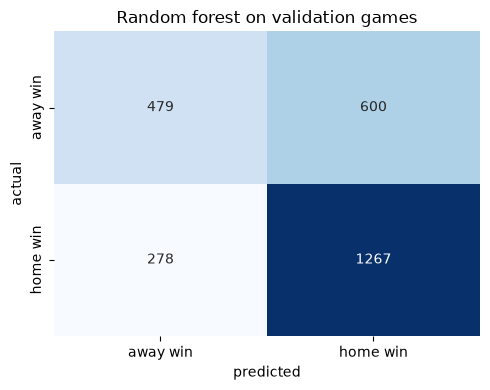

In [6]:
fig, ax = plt.subplots(figsize=(5, 4))
plot_cm(ax, y_val, val_prob, "Random forest on validation games")
plt.tight_layout()
plt.show()

### Step 6: observations
The random forest got 66.54% accuracy on validation. Always picking the home
team got 58.88%, so the forest improved accuracy by about 8 percentage points.
Its log loss was also lower (0.6143 compared with 0.6775), so its win
probabilities were better overall.

The confusion matrix shows that the forest correctly predicted 1,267 home
wins and 479 away wins. It caught about 82% of actual home wins and 44% of
actual away wins. Its most common mistake was predicting a home win when the away team won.

Training accuracy was 73.77%, about 7 percentage points higher than validation
accuracy. This gap suggests the forest may be overfitting to the training games.